# Digital Linear Modulation Schemes

## Signal Constellations (Alphabets)

Linear digital modulation schemes map $m$-bit tuples onto discrete symbols $X_i$ taken from an appropriate alphabet $\mathbb X$ with cardinality $M=2^m$. We distinguish between amplitude, phase and frequency modulation. Since only discrete values are considered for digital modulation,these schemes are termed in the following way.
* ASK: Amplitude Shift Keying 
* QAM: Quadrature Amplitude Modulation 
* PSK: Phase Shift Keying
* FSK: Frequency Shift Keying

While frequency modulation belongs to the class of non-linear modulation schemes and will not be considered in this Jupyter notebook, ASK, QAM und PSK are linear schemes. Their signal constellations are described in the figures below. For $M=16$, ASK arranges all symbols on the real axis resulting in a very dense packing. QAM instead exploits the complete complex plane and can achieve much larger Euclidean distances between symbols as ASK. Finally, PSK arranges all symbols on a circle, i.e. symbols differ only in their phases and have a constant magnitude.

In [7]:
import numpy as np
from modulation import int2bin, bin2gray
#import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# cardinality of modulation scheme
M = 16
m = int(np.round(np.log2(M)))

# symbol index
idx = np.arange(M)

# ASK alphabet
ask = M-1 - 2*idx
# ASK alphabet normlized to unit average power
ask_norm = ask / np.sqrt(np.sum(ask**2) / M)

# QAM alphabet
sqrtM = int(np.sqrt(M))
sqrt_idx = np.arange(sqrtM)
sqrt_ask = sqrtM-1 - 2*sqrt_idx
qam = np.outer(np.ones((sqrtM,1)),sqrt_ask) + (1j)*np.outer(sqrt_ask,np.ones((sqrtM,1)))
qam = np.reshape(qam,(M,1))

# QAM alphabet normalized to unit average power
qam_norm = qam / np.sqrt(np.sum(np.abs(qam)**2) / M)

# PSK alphabet
psk = np.cos(2*np.pi*idx/M) + (1j)*np.sin(2*np.pi*idx/M)

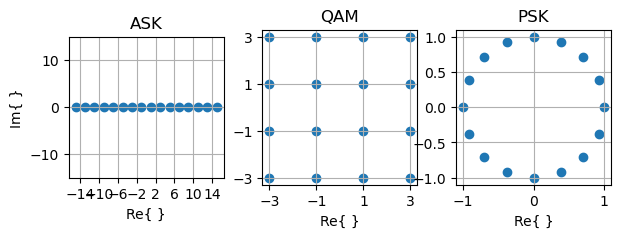

In [2]:
fig = plt.figure(figsize=(7,6))
plt.subplots_adjust(wspace=0.25)
ax = fig.add_subplot(131)
ax.scatter(np.real(ask), np.imag(ask), marker='o')
ax.set(adjustable='box', aspect='equal')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('ASK')
plt.grid(True)
plt.ylim((-15.0,15.0))
plt.xticks(4*(np.arange(M/2)-M/4+1)-2)

ax = fig.add_subplot(132)
ax.scatter(np.real(qam), np.imag(qam), marker='o')
ax.set(adjustable='box', aspect='equal')
plt.xlabel('Re{ }')
#plt.ylabel('Im{ }')
plt.title('QAM')
plt.grid(True)
plt.xticks(2*(np.arange(sqrtM)-sqrtM/2+1)-1)
plt.yticks(2*(np.arange(sqrtM)-sqrtM/2+1)-1)

ax = fig.add_subplot(133)
ax.scatter(np.real(psk), np.imag(psk), marker='o')
ax.set(adjustable='box', aspect='equal')
plt.xlabel('Re{ }')
#plt.ylabel('Im{ }')
plt.title('PSK')
plt.grid(True)


## Mapping

Next, we consider the mapping of bit tuples onto symbols in more detail. The figure below shows the binary representation of each symbol. We see that a simple counting from the most left to the most right symbol leads to binary representations which might distinguish in all $m=4$ bits between neighboring symbols. This leads to a high bit error probability because wrong decisions mainly occur when mixing up neighboring symbols.

In [5]:
# generate numbers from zero to M-1
u_dec = np.arange(M,dtype=int)
# generate corresponding bit pattern
u_bin = np.zeros((M,m),dtype=int)
for run in np.arange(M):
    u_bin[run,:] = int2bin(u_dec[run],m)

    

In [ ]:
ECCpath = 'ECCpython'
if (not ECCpath==None) and (not ECCpath in sys.path):
    sys.path.append(ECCpath)

from Modulation.modulation import Modulation

N_info_bits = 300
Mod = Modulation(m=3, coding_type='gray', modulation_type='ASK')

# def SIM(Nruns = 10, SNRdB = [0, 10], SNRdB_step = 1.0):
Nruns = 1000
SNRdB_range = np.arange(0, 20, 1)
SNR_range = 10 ** (SNRdB_range / 10)

bit_error = np.zeros((Nruns, len(SNRdB_range)))
symbol_error = np.zeros((Nruns, len(SNRdB_range)))

for loop in range(Nruns):
    for s, SNR in enumerate(SNR_range):
        # information bits
        u = np.random.randint(0, 2, N_info_bits)
        # modulation
        x = Mod.modulate(u)



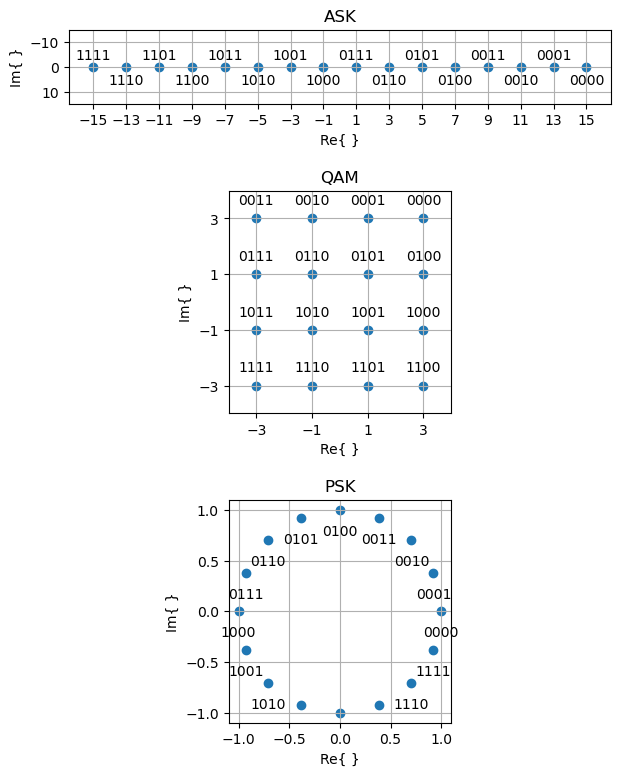

In [8]:
labels = np.empty(M,dtype=object)
for run1 in np.arange(M):
    labels[run1] = ''
    for run2 in np.arange(m): 
        labels[run1] = labels[run1] + str(u_bin[run1,run2])

fig = plt.figure(figsize=(7,9))
heights = [1, 2, 2]
spec = gridspec.GridSpec(nrows=3, ncols=1, height_ratios=[1, 3, 3])
      
plt.subplots_adjust(hspace=0.5)
ax = fig.add_subplot(spec[0])
ax.scatter(np.real(ask), np.imag(ask), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('ASK')
plt.grid(True)
plt.ylim((ask[0],ask[-1]))
plt.xticks(ask)
# print Gray label at each symbol
for run in np.arange(M):
    plt.annotate(labels[run], (M-1-2*run,5*(-1)**run+2),ha='center')
    
ax = fig.add_subplot(spec[1])
ax.set(adjustable='box', aspect='equal')
ax.scatter(np.real(qam), np.imag(qam), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('QAM')
plt.grid(True)
plt.xlim((-sqrtM,sqrtM))
plt.ylim((-sqrtM,sqrtM))
plt.xticks(sqrt_ask)
plt.yticks(sqrt_ask)
# print Gray label at each symbol
for run in np.arange(M):
    plt.annotate(labels[run], (np.real(qam[run]),np.imag(qam[run])+0.5),ha='center')
    
ax = fig.add_subplot(spec[2])
ax.set(adjustable='box', aspect='equal')
ax.scatter(np.real(psk), np.imag(psk), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('PSK')
plt.grid(True)
# print Gray label at each symbol
for run in np.arange(M):
    plt.annotate(labels[run], (np.real(psk[run]),np.imag(psk[run])-0.25),ha='center')    

Therefore, Gray mapping is usually applied. For Gray codes, the binary representation of neighboring symbols differs only in one bi. This minimizes the bit error probability. 

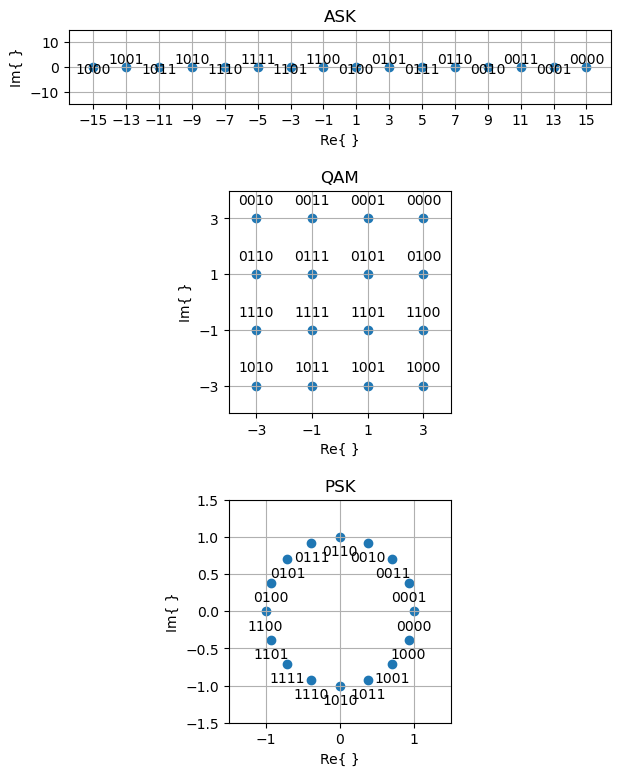

In [9]:
graylabels = np.empty(M,dtype=object)
for run1 in np.arange(M):
    u_gray = bin2gray(u_bin[run1,:].tolist())
    graylabels[run1] = ''
    for run2 in np.arange(m): 
        graylabels[run1] = graylabels[run1] + str(u_gray[run2])

# QAM: independent Gray mapping for real and imaginary parts
graylabelsASK = np.empty(sqrtM,dtype=object)
u_decASK = np.arange(sqrtM,dtype=int)
# generate corresponding bit pattern
for run1 in np.arange(sqrtM):
    u_binASK = int2bin(u_decASK[run1],int(m/2))
    u_grayASK = bin2gray(u_binASK.tolist())
    graylabelsASK[run1] = ''
    for run2 in np.arange(int(m/2)): 
        graylabelsASK[run1] = graylabelsASK[run1] + str(u_grayASK[run2])

# combine 2 ASK codewords to 1 QAM codeword
graylabelsQAM = np.empty(M,dtype=object)
for run1 in np.arange(sqrtM):
    for run2 in np.arange(sqrtM):
        graylabelsQAM[run1*sqrtM+run2] = graylabelsASK[run1]+graylabelsASK[run2]

fig = plt.figure(figsize=(7,9))
spec = gridspec.GridSpec(nrows=3, ncols=1, height_ratios=[1, 3, 3])

plt.subplots_adjust(hspace=0.5)
ax = fig.add_subplot(spec[0])
ax.scatter(np.real(ask), np.imag(ask), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('ASK')
plt.grid(True)
plt.ylim((-15.0,15.0))
plt.xticks(ask)
# print label at each symbol
for run in np.arange(M):
    plt.annotate(graylabels[run], (M-1-2*run,2*(-1)**run-0.5),ha='center')
    
ax = fig.add_subplot(spec[1])
ax.set(adjustable='box', aspect='equal')
ax.scatter(np.real(qam), np.imag(qam), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('QAM')
plt.grid(True)
plt.xlim((-sqrtM,sqrtM))
plt.ylim((-sqrtM,sqrtM))
plt.xticks(sqrt_ask)
plt.yticks(sqrt_ask)
# print label at each symbol
for run in np.arange(M):
    plt.annotate(graylabelsQAM[run], (np.real(qam[run]),np.imag(qam[run])+0.5),ha='center')
    
ax = fig.add_subplot(spec[2])
ax.set(adjustable='box', aspect='equal')
ax.scatter(np.real(psk), np.imag(psk), marker='o')
plt.xlabel('Re{ }')
plt.ylabel('Im{ }')
plt.title('PSK')
plt.grid(True)
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)
# print label at each symbol
for run in np.arange(M):
    plt.annotate(graylabels[run], (np.real(psk[run]),np.imag(psk[run])-0.25),ha='center')        